<a href="https://colab.research.google.com/github/yeyevtushenko/Methods-and-Technologies-of-Computational-Intelligence/blob/main/%D0%9C%D0%B5%D1%82%D0%BE%D0%B4%D0%B8_%D1%82%D0%B0_%D1%82%D0%B5%D1%85%D0%BD%D0%BE%D0%BB%D0%BE%D0%B3%D1%96%D1%97_%D0%BE%D0%B1%D1%87%D0%B8%D1%81%D0%BB%D1%8E%D0%B2%D0%B0%D0%BB%D1%8C%D0%BD%D0%BE%D0%B3%D0%BE_%D1%96%D0%BD%D1%82%D0%B5%D0%BB%D0%B5%D0%BA%D1%82%D1%83_%D0%97%D0%9A_61%D0%9F%D0%9C_%D0%84%D0%B2%D1%82%D1%83%D1%88%D0%B5%D0%BD%D0%BA%D0%BE_%D0%BF%D1%80%D0%BE%D0%B4%D0%B2%D0%B8%D0%BD%D1%83%D1%82%D0%B8%D0%B9_%D0%9B%D0%B0%D0%B1%E2%84%962.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Імпорт бібліотек

In [1]:
%pip install -q ucimlrepo pyswarms

import time
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.svm import SVC
from sklearn.metrics import balanced_accuracy_score, classification_report, confusion_matrix, roc_auc_score

import pyswarms as ps

warnings.filterwarnings('ignore')

# Завдання 1. Дані, baseline та базова конфігурація Global-Best PSO

> Відтворити baseline та базову конфігурацію Global-Best PSO.

Shape: (303, 13)

Class distribution:
num
0    164
1    139
Name: count, dtype: int64

Missing values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
dtype: int64

Data types:
age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca          float64
thal        float64
dtype: object


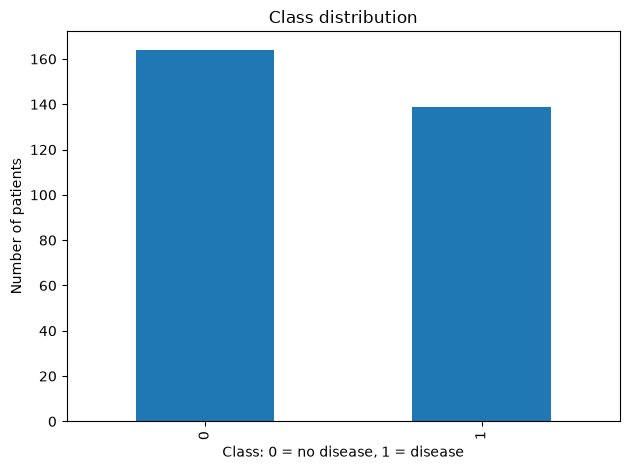

In [ ]:
heart = fetch_ucirepo(id=45)

X = heart.data.features.copy()
y_raw = heart.data.targets.iloc[:, 0].copy()
y = (y_raw > 0).astype(int)

print("Shape:", X.shape)
print("\nClass distribution:")
print(y.value_counts())
print("\nMissing values:")
print(X.isna().sum())
print("\nData types:")
print(X.dtypes)

y.value_counts().sort_index().plot(kind="bar")
plt.xlabel("Class: 0 = no disease, 1 = disease")
plt.ylabel("Number of patients")
plt.title("Class distribution")
plt.tight_layout()
plt.show()

Набір містить 303 пацієнти і 13 ознак. Початкова цільова змінна `num` приведена до бінарної (`num > 0` означає наявність захворювання): 164 пацієнти без захворювання (клас 0) і 139 із захворюванням (клас 1), тобто класи майже збалансовані. Пропущені значення є лише у двох ознаках: `ca` (4) і `thal` (2). Числові ознаки: `age`, `trestbps`, `chol`, `thalach`, `oldpeak`, `ca`; решта ознак цілочисельні й розглядаються як категоріальні.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)

categorical_cols = ["sex", "cp", "fbs", "restecg", "exang", "slope", "thal"]
numeric_cols = [c for c in X.columns if c not in categorical_cols]

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipe, numeric_cols),
    ("cat", categorical_pipe, categorical_cols)
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("Train:", X_train.shape)
print("Test:", X_test.shape)
print("Числові ознаки:", numeric_cols)

Train: (242, 13)
Test: (61, 13)
Числові ознаки: ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'ca']


Дані розбито на навчальну (242 об'єкти) і тестову (61 об'єкт) частини зі стратифікацією, фіксованим `random_state`. Числові ознаки обробляються медіанним заповненням пропусків і стандартизацією, категоріальні заповненням найчастішим значенням і One-Hot кодуванням. Усе це входить до `Pipeline`, тому на кожному фолді крос-валідації імп'ютер, скейлер і кодувальник навчаються лише на навчальній частині фолду, а тестові дані ніколи не використовуються для підбору параметрів.

In [ ]:
def make_pipeline(C=1.0, gamma="scale", class_weight=None, probability=False):
    return Pipeline([
        ("prep", preprocessor),
        ("clf", SVC(kernel="rbf", C=C, gamma=gamma, class_weight=class_weight, probability=probability, random_state=42))
    ])

baseline_model = make_pipeline(probability=True)
baseline_model.fit(X_train, y_train)

pred_base = baseline_model.predict(X_test)
prob_base = baseline_model.predict_proba(X_test)[:, 1]

baseline_bacc = balanced_accuracy_score(y_test, pred_base)
baseline_auc = roc_auc_score(y_test, prob_base)
baseline_cv = cross_val_score(make_pipeline(), X_train, y_train, cv=cv, scoring="balanced_accuracy").mean()

print("Baseline CV BAcc:", baseline_cv)
print("Baseline BAcc:", baseline_bacc)
print("Baseline ROC-AUC:", baseline_auc)
print(classification_report(y_test, pred_base, digits=4))
print(confusion_matrix(y_test, pred_base))

Baseline CV BAcc: 0.8249163879598662
Baseline BAcc: 0.9036796536796536
Baseline ROC-AUC: 0.9610389610389611
              precision    recall  f1-score   support

           0     0.9355    0.8788    0.9062        33
           1     0.8667    0.9286    0.8966        28

    accuracy                         0.9016        61
   macro avg     0.9011    0.9037    0.9014        61
weighted avg     0.9039    0.9016    0.9018        61

[[29  4]
 [ 2 26]]


Baseline (SVC з `C = 1`, `gamma = "scale"`, без вагових коефіцієнтів) дає CV Balanced Accuracy 0.8249 на навчальній вибірці, Balanced Accuracy 0.9037 і ROC-AUC 0.9610 на тесті. Матриця помилок: 29 з 33 здорових і 26 з 28 хворих класифіковано правильно (4 хибнопозитивних і 2 пропущені хворих). Тестова оцінка помітно вища за CV, що пов'язано з малим розміром тесту (61 об'єкт; одна помилка змінює Balanced Accuracy приблизно на 1.5 – 1.8 п.п.), тому порівнювати слід оцінки одного типу.

In [ ]:
def decode_particle(position):
    log10_C, log10_gamma, positive_weight = position
    return 10 ** log10_C, 10 ** log10_gamma, float(positive_weight)

eval_counter = [0]

def objective_function(particles):
    costs = []
    for position in particles:
        eval_counter[0] += 1
        C, gamma, positive_weight = decode_particle(position)
        model = make_pipeline(C=C, gamma=gamma, class_weight={0: 1.0, 1: positive_weight})
        scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="balanced_accuracy")
        costs.append(1.0 - scores.mean())
    return np.array(costs)

lower_bounds = np.array([-2.0, -4.0, 0.5])
upper_bounds = np.array([3.0, 1.0, 3.0])
bounds = (lower_bounds, upper_bounds)
N_PARTICLES = 20
N_ITERATIONS = 20

def diversity(history):
    scale = upper_bounds - lower_bounds
    return [float(np.mean(np.linalg.norm((p - p.mean(axis=0)) / scale, axis=1))) for p in history]

def run_pso(kind="global", seed=42, w=0.7, c1=1.5, c2=1.5, n_particles=N_PARTICLES, iters=N_ITERATIONS,
            k=5, p=2, verbose=False):
    np.random.seed(seed)
    options = {"c1": c1, "c2": c2, "w": w}
    eval_counter[0] = 0
    if kind == "global":
        optimizer = ps.single.GlobalBestPSO(n_particles=n_particles, dimensions=3, options=options, bounds=bounds)
    else:
        optimizer = ps.single.LocalBestPSO(n_particles=n_particles, dimensions=3, options={**options, "k": k, "p": p},
                                           bounds=bounds)
    start = time.time()
    cost, position = optimizer.optimize(objective_function, iters=iters, verbose=verbose)
    elapsed = time.time() - start
    return {"cost": cost, "cv": 1.0 - cost, "position": position, "time": elapsed, "evals": eval_counter[0],
            "history": list(optimizer.cost_history), "diversity": diversity(optimizer.pos_history),
            "n_particles": n_particles, "kind": kind, "w": w, "c1": c1, "c2": c2, "seed": seed}

options = {"c1": 1.5, "c2": 1.5, "w": 0.7}
pso_main = run_pso(seed=42, verbose=True)
optimizer_cost_history = pso_main["history"]

2026-11-24 12:44:27,995 - pyswarms.single.global_best - INFO - Optimize for 20 iters with {'c1': 1.5, 'c2': 1.5, 'w': 0.7}


pyswarms.single.global_best:   0%|          |0/20

pyswarms.single.global_best:   0%|          |0/20, best_cost=0.172

pyswarms.single.global_best:   5%|▌         |1/20, best_cost=0.172

pyswarms.single.global_best:   5%|▌         |1/20, best_cost=0.172

pyswarms.single.global_best:  10%|█         |2/20, best_cost=0.172

... (34 outputs left out)

pyswarms.single.global_best:  95%|█████████▌|19/20, best_cost=0.148

pyswarms.single.global_best: 100%|██████████|20/20, best_cost=0.148

pyswarms.single.global_best: 100%|██████████|20/20, best_cost=0.148


2026-11-24 12:44:51,158 - pyswarms.single.global_best - INFO - Optimization finished | best cost: 0.14751641273380423, best pos: [ 0.43441694 -2.55862815  1.00900753]


Базова конфігурація Global-Best PSO відповідає теорії: 20 частинок, 20 ітерацій, c1 = 1.5, c2 = 1.5, w = 0.7, межі пошуку log10(C) від −2 до 3, log10(gamma) від −4 до 1 та вага позитивного класу від 0.5 до 3.0. Кожна частинка оцінюється через `1 − CV Balanced Accuracy` (5-кратна стратифікована крос-валідація на навчальній частині). Теорія використовує `n_jobs=-1` у `cross_val_score`, тут оцінювання виконується в одному процесі, бо дані малі, а також додатково зберігається історія позицій частинок, щоб виміряти різноманіття рою.

# Завдання 2. Знайдені параметри

> Показати знайдені PSO значення C, gamma та positive class weight.

In [ ]:
best_C, best_gamma, best_weight = decode_particle(pso_main["position"])

print("Best cost:", pso_main["cost"])
print("Best CV BAcc:", pso_main["cv"])
print("C:", best_C)
print("gamma:", best_gamma)
print("positive class weight:", best_weight)
print("Optimization time, s:", pso_main["time"])
print("Кількість викликів objective function:", pso_main["evals"])

Best cost: 0.14751641273380423
Best CV BAcc: 0.8524835872661958
C: 2.7190483830826855
gamma: 0.002762942512869754
positive class weight: 1.0090075307639321
Optimization time, s: 23.163182258605957
Кількість викликів objective function: 400


Global-Best PSO (seed 42) знайшов `C ≈ 2.72`, `gamma ≈ 0.0028` і вагу позитивного класу ≈ 1.009 з CV Balanced Accuracy 0.8525 проти 0.8249 для baseline (приріст близько 2.8 п.п.). Вага позитивного класу майже дорівнює 1, тобто ваги класів фактично не змінилися, що природно для майже збалансованих класів. Було виконано 400 викликів objective function (20 частинок × 20 ітерацій), час 23.2 с.

# Завдання 3. Графік збіжності

> Побудувати графік збіжності PSO.

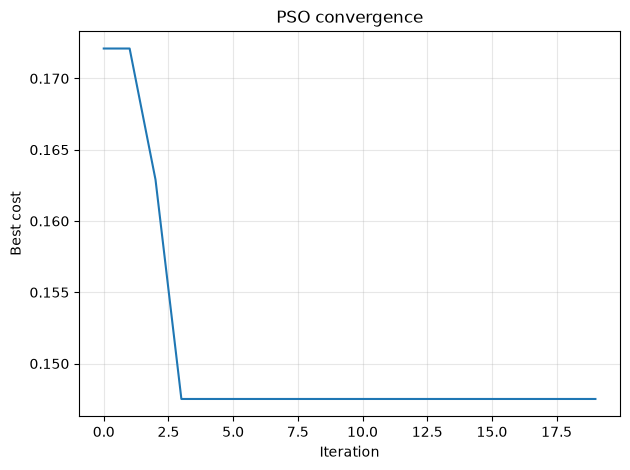

Cost: початковий 0.1721 , фінальний 0.1475
Плато починається з ітерації 3
Покращення за останні 10 ітерацій: 0.0
Різноманіття рою (середня відстань до центру, нормована): початок 0.472 , кінець 0.239


In [ ]:
history = np.array(pso_main["history"])
plt.plot(history)
plt.xlabel("Iteration")
plt.ylabel("Best cost")
plt.title("PSO convergence")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

plateau = int(np.argmax(history <= history[-1] + 1e-12))
print("Cost: початковий", round(history[0], 4), ", фінальний", round(history[-1], 4))
print("Плато починається з ітерації", plateau)
print("Покращення за останні 10 ітерацій:", round(history[-11] - history[-1], 5))
print("Різноманіття рою (середня відстань до центру, нормована): початок", round(pso_main["diversity"][0], 3),
      ", кінець", round(pso_main["diversity"][-1], 3))

Найкращий cost знизився з 0.1721 на першій ітерації до 0.1475, останнє покращення відбулось на 3-й ітерації, а за останні 10 ітерацій приросту немає: далі рій лише уточнює пошук поблизу знайденого розв'язку, не покращуючи його. Різноманіття рою (середня нормована відстань частинок до центру) скоротилось з 0.472 до 0.239, тобто приблизно вдвічі: рій стягується до області кращих значень, але не збігається в одну точку. Швидке плато означає, що для цієї задачі з трьома параметрами 20 ітерацій більш ніж достатньо в межах цього запуску, але це не гарантує, що знайдено глобальний оптимум.

# Завдання 4. Експерименти

> Провести всі експерименти з розділу 15. Для кожної серії експериментів змінювати лише досліджуваний параметр, інші залишати фіксованими.

> 1. Inertia weight w: 0.3; 0.7; 1.1. Що аналізувати: збіжність, best CV BAcc, стабільність.
> 2. Cognitive/social balance (c1, c2): (2.5, 0.5); (1.5, 1.5); (0.5, 2.5). Що аналізувати: індивідуальний vs колективний пошук.
> 3. Розмір рою: 10; 20; 40 particles. Що аналізувати: якість, час, швидкість збіжності.
> 4. GlobalBestPSO та LocalBestPSO. Що аналізувати: ризик передчасної збіжності.
> 5. Повторні запуски: не менше 5 random seeds. Що аналізувати: mean ± std найкращого CV BAcc.
> 6. PSO vs Random Search: однаковий бюджет. Що аналізувати: best score, час, швидкість пошуку.

In [ ]:
SEEDS = [0, 1, 2, 3, 4]
runs = {}

def get_run(kind="global", w=0.7, c1=1.5, c2=1.5, n_particles=20, seed=0):
    key = (kind, w, c1, c2, n_particles, seed)
    if key not in runs:
        runs[key] = run_pso(kind=kind, seed=seed, w=w, c1=c1, c2=c2, n_particles=n_particles)
    return runs[key]

def aggregate(results):
    plateaus = [int(np.argmax(np.array(r["history"]) <= r["history"][-1] + 1e-12)) for r in results]
    return {
        "best CV BAcc": f"{np.mean([r['cv'] for r in results]):.4f} ± {np.std([r['cv'] for r in results]):.4f}",
        "плато з ітерації": f"{np.mean(plateaus):.1f}",
        "різноманіття (кінець)": f"{np.mean([r['diversity'][-1] for r in results]):.3f}",
        "час, с": round(np.mean([r["time"] for r in results]), 1),
        "оцінок": int(np.mean([r["evals"] for r in results])),
    }

def mean_curve(results):
    return np.mean([1.0 - np.array(r["history"]) for r in results], axis=0)

Для всіх серій використовуються 5 random seeds (0 – 4), що відповідає експерименту 5, а в кожній серії змінюється лише досліджуваний параметр, решта залишається з базової конфігурації (w = 0.7, c1 = c2 = 1.5, 20 частинок, 20 ітерацій, Global-Best). Для експериментів порівнюється лише крос-валідаційна якість, а тестова вибірка в них не використовується.

# Експеримент 1. Inertia weight w

In [ ]:
exp1 = {}
for w in [0.3, 0.7, 1.1]:
    exp1[f"w = {w}"] = [get_run(w=w, seed=s) for s in SEEDS]
print(pd.DataFrame({k: aggregate(v) for k, v in exp1.items()}).T.to_string())

            best CV BAcc плато з ітерації різноманіття (кінець) час, с оцінок
w = 0.3  0.8562 ± 0.0000              9.6                 0.120   22.4    400
w = 0.7  0.8494 ± 0.0042             14.8                 0.374   22.8    400
w = 1.1  0.8471 ± 0.0049              7.8                 0.452   22.9    400


Найкращий середній CV Balanced Accuracy дає w = 0.3 (0.8562 ± 0.0000), далі w = 0.7 (0.8494 ± 0.0042) і w = 1.1 (0.8471 ± 0.0049). Нульовий розкид при w = 0.3 означає, що всі 5 запусків дійшли до одного й того ж значення, а різноманіття рою в кінці було найменшим (0.120 проти 0.374 і 0.452): мала інерція швидко стягує рій. Великій інерції відповідає найбільше різноманіття в кінці (0.452), тобто рій лишається розсіяним і не встигає зосередитись. Час практично однаковий (22.4 – 22.9 с), бо він визначається кількістю оцінок (400), а не значенням w. Різниці між значеннями w невеликі (до 0.9 п.п.), але w = 0.3 стабільніший і не гірший за інші.

# Експеримент 2. Баланс когнітивної та соціальної складових

In [ ]:
exp2 = {}
for c1, c2 in [(2.5, 0.5), (1.5, 1.5), (0.5, 2.5)]:
    exp2[f"c1 = {c1}, c2 = {c2}"] = [get_run(c1=c1, c2=c2, seed=s) for s in SEEDS]
print(pd.DataFrame({k: aggregate(v) for k, v in exp2.items()}).T.to_string())

                       best CV BAcc плато з ітерації різноманіття (кінець) час, с оцінок
c1 = 2.5, c2 = 0.5  0.8514 ± 0.0032             13.4                 0.273   22.6    400
c1 = 1.5, c2 = 1.5  0.8494 ± 0.0042             14.8                 0.374   22.8    400
c1 = 0.5, c2 = 2.5  0.8469 ± 0.0039             10.4                 0.368   22.8    400


Середній CV Balanced Accuracy: 0.8514 ± 0.0032 для (2.5, 0.5), 0.8494 ± 0.0042 для (1.5, 1.5) і 0.8469 ± 0.0039 для (0.5, 2.5). Тобто переважання когнітивної складової (індивідуальний пошук) дало трохи кращий результат, ніж переважання соціальної (колективний пошук), але різниця між крайніми варіантами (0.0045) порівнянна з розкидом між запусками (≈ 0.004), тому однозначного висновку зробити не можна. Різноманіття наприкінці при (2.5, 0.5) найменше (0.273), а при двох інших значеннях майже однакове (0.374 і 0.368). Час однаковий.

# Експеримент 3. Розмір рою

In [ ]:
exp3 = {}
for n in [10, 20, 40]:
    exp3[f"{n} частинок"] = [get_run(n_particles=n, seed=s) for s in SEEDS]
print(pd.DataFrame({k: aggregate(v) for k, v in exp3.items()}).T.to_string())

                best CV BAcc плато з ітерації різноманіття (кінець) час, с оцінок
10 частинок  0.8482 ± 0.0052             14.8                 0.279   11.3    200
20 частинок  0.8494 ± 0.0042             14.8                 0.374   22.8    400
40 частинок  0.8554 ± 0.0015             15.4                 0.320   45.1    800


Із збільшенням рою середня якість зростає: 0.8482 ± 0.0052 (10 частинок), 0.8494 ± 0.0042 (20) і 0.8554 ± 0.0015 (40), а розкид зменшується. Час зростає пропорційно кількості частинок (11.3, 22.8 і 45.1 с), бо число ітерацій фіксоване і кількість оцінок дорівнює 200, 400 і 800. Тобто покращення при 40 частинках отримано за подвоєного бюджету, і порівнювати ці варіанти за якістю без урахування бюджету некоректно. Ітерація, з якої починається плато, майже не залежить від розміру рою (14.8, 14.8 і 15.4).

# Експеримент 4. Global-Best та Local-Best PSO

In [ ]:
exp4 = {"Global-Best": [get_run(seed=s) for s in SEEDS],
        "Local-Best (k = 5, p = 2)": [get_run(kind="local", seed=s) for s in SEEDS]}
print(pd.DataFrame({k: aggregate(v) for k, v in exp4.items()}).T.to_string())

                              best CV BAcc плато з ітерації різноманіття (кінець) час, с оцінок
Global-Best                0.8494 ± 0.0042             14.8                 0.374   22.8    400
Local-Best (k = 5, p = 2)  0.8496 ± 0.0022             12.4                 0.351   22.5    400


Global-Best і Local-Best дають практично однакову середню якість: 0.8494 ± 0.0042 і 0.8496 ± 0.0022, при цьому розкид Local-Best менший, а діапазон результатів вужчий (0.8466 – 0.8525 проти 0.8439 – 0.8562). Різноманіття рою наприкінці також близьке (0.374 і 0.351), тому в цьому експерименті ознак передчасної збіжності Global-Best порівняно з Local-Best не видно. Це може бути пов'язано з малою розмірністю простору (три параметри) і з невеликим значенням `k = 5` для рою із 20 частинок.

# Експеримент 5. Повторні запуски

        best CV BAcc       C   gamma  вага класу 1
seed 0        0.8478  24.338  0.0003         1.002
seed 1        0.8439   0.551  0.0352         0.941
seed 2        0.8516   1.022  0.0094         0.940
seed 3        0.8562   2.293  0.0031         0.976
seed 4        0.8473  12.771  0.0008         0.938
{'best CV BAcc': '0.8494 ± 0.0042', 'плато з ітерації': '14.8', 'різноманіття (кінець)': '0.374', 'час, с': np.float64(22.8), 'оцінок': 400}


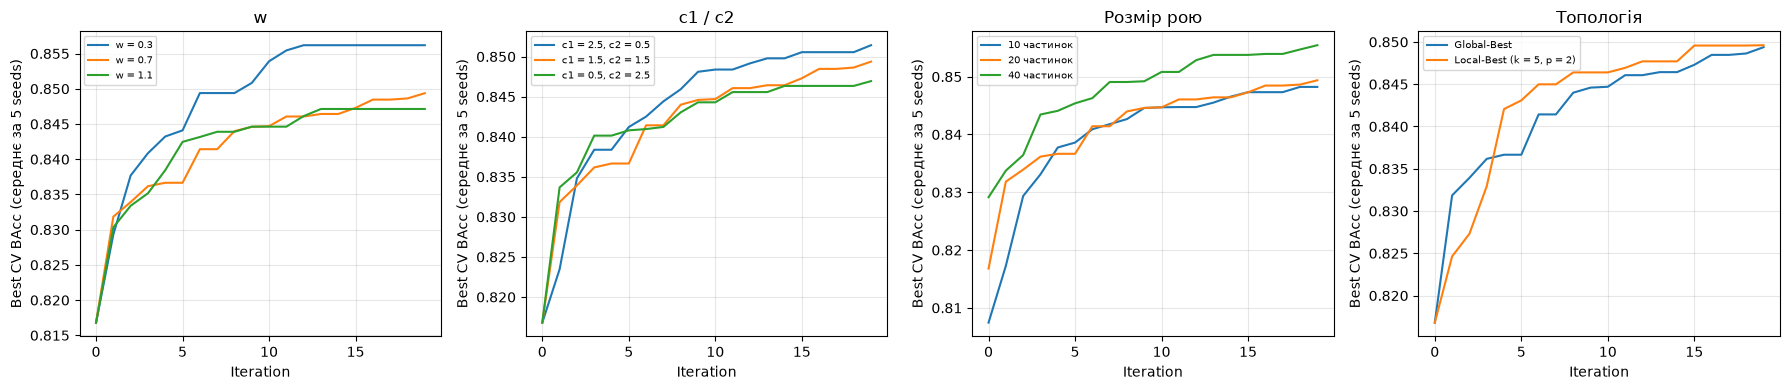

In [ ]:
base_runs = exp1["w = 0.7"]
print(pd.DataFrame({f"seed {r['seed']}": {"best CV BAcc": round(r["cv"], 4), "C": round(decode_particle(r["position"])[0], 3),
                                            "gamma": round(decode_particle(r["position"])[1], 4),
                                            "вага класу 1": round(decode_particle(r["position"])[2], 3)}
                    for r in base_runs}).T.to_string())
print(aggregate(base_runs))

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (title, group) in zip(axes, [("w", exp1), ("c1 / c2", exp2), ("Розмір рою", exp3), ("Топологія", exp4)]):
    for name, res in group.items():
        ax.plot(mean_curve(res), label=name)
    ax.set_title(title)
    ax.set_xlabel("Iteration")
    ax.set_ylabel("Best CV BAcc (середнє за 5 seeds)")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

За 5 seeds best CV Balanced Accuracy дорівнює 0.8494 ± 0.0042 (від 0.8439 до 0.8562). Знайдені параметри між запусками сильно відрізняються: `C` від 0.55 до 24.3, `gamma` від 0.0003 до 0.035, тоді як вага класу 1 лежить у вузькому діапазоні 0.94 – 1.00. При цьому якість майже однакова, тобто різні комбінації `C` і `gamma` дають близькі значення CV Balanced Accuracy, і поверхня функції якості в цій області має широке пласке плато (взаємодія `C` та `gamma`). Через це найкращі значення параметрів з одного запуску не слід інтерпретувати як єдині оптимальні.

# Експеримент 6. PSO проти Random Search

Бюджет (кількість оцінок objective function): 400


                    best CV BAcc час, с оцінок
Global-Best PSO  0.8494 ± 0.0042   22.8    400
Random Search    0.8454 ± 0.0038   22.9    400
           PSO  Random Search
seed 0  0.8478         0.8453
seed 1  0.8439         0.8460
seed 2  0.8516         0.8400
seed 3  0.8562         0.8516
seed 4  0.8473         0.8441


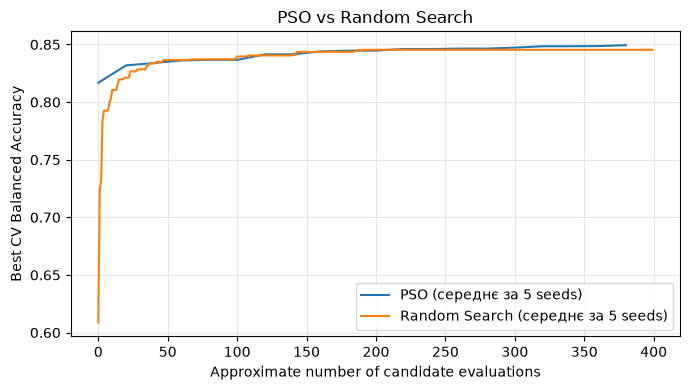

In [ ]:
def random_search(seed, budget, verbose=False):
    rng = np.random.default_rng(seed)
    best_cost, best_position, history = np.inf, None, []
    start = time.time()
    for _ in range(budget):
        position = rng.uniform(lower_bounds, upper_bounds)
        cost = objective_function(position.reshape(1, -1))[0]
        if cost < best_cost:
            best_cost, best_position = cost, position.copy()
        history.append(best_cost)
    return {"cost": best_cost, "cv": 1.0 - best_cost, "position": best_position, "time": time.time() - start,
            "history": history, "evals": budget, "seed": seed}

BUDGET = base_runs[0]["evals"]
print("Бюджет (кількість оцінок objective function):", BUDGET)
rs_runs = [random_search(s, BUDGET) for s in SEEDS]
rs_main = random_search(42, BUDGET)

print(pd.DataFrame({
    "Global-Best PSO": {"best CV BAcc": f"{np.mean([r['cv'] for r in base_runs]):.4f} ± {np.std([r['cv'] for r in base_runs]):.4f}",
                        "час, с": round(np.mean([r["time"] for r in base_runs]), 1), "оцінок": BUDGET},
    "Random Search": {"best CV BAcc": f"{np.mean([r['cv'] for r in rs_runs]):.4f} ± {np.std([r['cv'] for r in rs_runs]):.4f}",
                      "час, с": round(np.mean([r["time"] for r in rs_runs]), 1), "оцінок": BUDGET}}).T.to_string())
print(pd.DataFrame({"PSO": [round(r["cv"], 4) for r in base_runs], "Random Search": [round(r["cv"], 4) for r in rs_runs]},
                   index=[f"seed {s}" for s in SEEDS]).to_string())

plt.figure(figsize=(7, 4))
x_pso = np.arange(len(base_runs[0]["history"])) * N_PARTICLES
plt.plot(x_pso, mean_curve(base_runs), label="PSO (середнє за 5 seeds)")
plt.plot(np.arange(BUDGET), np.mean([1.0 - np.array(r["history"]) for r in rs_runs], axis=0), label="Random Search (середнє за 5 seeds)")
plt.xlabel("Approximate number of candidate evaluations")
plt.ylabel("Best CV Balanced Accuracy")
plt.title("PSO vs Random Search")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

За однакового бюджету 400 оцінок PSO дає 0.8494 ± 0.0042, а Random Search 0.8454 ± 0.0038, час майже однаковий (22.8 і 22.9 с, адже майже весь час іде на крос-валідацію). PSO кращий у 4 із 5 seeds (у seed 1 кращий Random Search: 0.8460 проти 0.8439). Різниця середніх (0.004) порівнянна з розкидом між запусками, тому перевага PSO над випадковим пошуком є невеликою і не підтверджена статистично. Для простору з трьох параметрів випадковий пошук із 400 точок уже непогано покриває область.

# Завдання 6. Порівняння Global-Best PSO, Local-Best PSO та Random Search

> Порівняти Global-Best PSO, Local-Best PSO та Random Search.

In [ ]:
compare = {
    "Global-Best PSO": exp4["Global-Best"],
    "Local-Best PSO": exp4["Local-Best (k = 5, p = 2)"],
    "Random Search": rs_runs,
}
print(pd.DataFrame({n: {"best CV BAcc": f"{np.mean([r['cv'] for r in v]):.4f} ± {np.std([r['cv'] for r in v]):.4f}",
                         "мін – макс": f"{min(r['cv'] for r in v):.4f} – {max(r['cv'] for r in v):.4f}",
                         "час, с": round(np.mean([r['time'] for r in v]), 1), "оцінок": int(np.mean([r['evals'] for r in v]))}
                    for n, v in compare.items()}).T.to_string())

                    best CV BAcc       мін – макс час, с оцінок
Global-Best PSO  0.8494 ± 0.0042  0.8439 – 0.8562   22.8    400
Local-Best PSO   0.8496 ± 0.0022  0.8466 – 0.8525   22.5    400
Random Search    0.8454 ± 0.0038  0.8400 – 0.8516   22.9    400


Global-Best PSO та Local-Best PSO мають практично однакову середню якість (0.8494 і 0.8496), Random Search трохи нижчу (0.8454). Local-Best має найменший розкид (± 0.0022), а Global-Best — найбільший діапазон (0.8439 – 0.8562). Усі три методи витрачають однакову кількість оцінок і майже однаковий час, тому вибір між ними за ціною неважливий, а різниця в якості на цій задачі мала.

# Завдання 7. Оцінка найкращої конфігурації на тестовій вибірці

> Найкращу конфігурацію один раз оцінити на відкладеному test set.

In [ ]:
configs = {
    "w = 0.3": exp1["w = 0.3"], "w = 0.7 (базова)": exp1["w = 0.7"], "w = 1.1": exp1["w = 1.1"],
    "c1 = 2.5, c2 = 0.5": exp2["c1 = 2.5, c2 = 0.5"], "c1 = 0.5, c2 = 2.5": exp2["c1 = 0.5, c2 = 2.5"],
    "Local-Best": exp4["Local-Best (k = 5, p = 2)"],
}
config_scores = {n: np.mean([r["cv"] for r in v]) for n, v in configs.items()}
print("Середній best CV BAcc за 5 seeds (бюджет 20 частинок × 20 ітерацій для всіх):")
for n, s in sorted(config_scores.items(), key=lambda kv: -kv[1]):
    print(f"  {n}: {s:.4f}")

best_config = max(config_scores, key=config_scores.get)
best_run = max(configs[best_config], key=lambda r: r["cv"])
print("\nНайкраща конфігурація:", best_config, ", запуск seed", best_run["seed"], ", CV BAcc", round(best_run["cv"], 4))

def final_evaluation(position):
    C, gamma, weight = decode_particle(position)
    model = make_pipeline(C=C, gamma=gamma, class_weight={0: 1.0, 1: weight}, probability=True)
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    return balanced_accuracy_score(y_test, pred), roc_auc_score(y_test, prob), confusion_matrix(y_test, pred), pred

best_bacc, best_auc, best_cm, best_pred = final_evaluation(best_run["position"])
C, gamma, weight = decode_particle(best_run["position"])
print("C:", C, ", gamma:", gamma, ", вага класу 1:", weight)
print("Test BAcc:", best_bacc, ", ROC-AUC:", best_auc)
print(classification_report(y_test, best_pred, digits=4))
print(best_cm)

Середній best CV BAcc за 5 seeds (бюджет 20 частинок × 20 ітерацій для всіх):
  w = 0.3: 0.8562
  c1 = 2.5, c2 = 0.5: 0.8514
  Local-Best: 0.8496
  w = 0.7 (базова): 0.8494
  w = 1.1: 0.8471
  c1 = 0.5, c2 = 2.5: 0.8469

Найкраща конфігурація: w = 0.3 , запуск seed 0 , CV BAcc 0.8562
C: 13.925675023445725 , gamma: 0.0004917551058069747 , вага класу 1: 1.008756346216487
Test BAcc: 0.933982683982684 , ROC-AUC: 0.9621212121212122
              precision    recall  f1-score   support

           0     0.9394    0.9394    0.9394        33
           1     0.9286    0.9286    0.9286        28

    accuracy                         0.9344        61
   macro avg     0.9340    0.9340    0.9340        61
weighted avg     0.9344    0.9344    0.9344        61

[[31  2]
 [ 2 26]]


За середнім CV Balanced Accuracy найкращою виявилась конфігурація w = 0.3 (0.8562), її запуск із seed 0 вибрано лише за крос-валідацією, без перегляду тесту. Отримані параметри: `C ≈ 13.9`, `gamma ≈ 0.00049`, вага позитивного класу ≈ 1.009. На тесті вона дає Balanced Accuracy 0.9340 і ROC-AUC 0.9621 проти 0.9037 і 0.9610 для baseline: з 61 об'єкта помилились 4 (2 хибнопозитивних і 2 пропущені хворих) замість 6. Приріст на тесті складає два об'єкти, тому це скоріше сумісна з baseline оцінка, ніж доказ переваги.

# Завдання 8. Підсумкова таблиця

> Побудувати підсумкову таблицю з CV BAcc, test BAcc, ROC-AUC, часом та computational budget.

In [ ]:
pso_bacc, pso_auc, _, _ = final_evaluation(pso_main["position"])
local_main = run_pso(kind="local", seed=42)
local_bacc, local_auc, _, _ = final_evaluation(local_main["position"])
rs_bacc, rs_auc, _, _ = final_evaluation(rs_main["position"])

rows = [
    ("Baseline (C = 1, gamma = scale)", baseline_cv, baseline_bacc, baseline_auc, 0.0, 0),
    ("Global-Best PSO (seed 42)", pso_main["cv"], pso_bacc, pso_auc, pso_main["time"], pso_main["evals"]),
    ("Local-Best PSO (seed 42)", local_main["cv"], local_bacc, local_auc, local_main["time"], local_main["evals"]),
    ("Random Search (seed 42)", rs_main["cv"], rs_bacc, rs_auc, rs_main["time"], rs_main["evals"]),
    (f"Найкраща конфігурація ({best_config}, seed {best_run['seed']})", best_run["cv"], best_bacc, best_auc,
     best_run["time"], best_run["evals"]),
]
summary = pd.DataFrame(rows, columns=["Метод", "CV BAcc", "Test BAcc", "ROC-AUC", "Час, с", "Бюджет (оцінок)"])
print(summary.round(4).to_string(index=False))

                                  Метод  CV BAcc  Test BAcc  ROC-AUC  Час, с  Бюджет (оцінок)
        Baseline (C = 1, gamma = scale)   0.8249     0.9037   0.9610  0.0000                0
              Global-Best PSO (seed 42)   0.8525     0.9188   0.9610 23.1632              400
               Local-Best PSO (seed 42)   0.8448     0.8734   0.9567 22.6553              400
                Random Search (seed 42)   0.8385     0.8734   0.9545 22.8639              400
Найкраща конфігурація (w = 0.3, seed 0)   0.8562     0.9340   0.9621 22.3256              400


У таблиці CV Balanced Accuracy усіх оптимізованих варіантів (0.8385 – 0.8562) вище, ніж baseline (0.8249), але вимірювання в CV є тією самою величиною, яку оптимізували, тому вона дещо завищена. На тесті картина змішана: Global-Best PSO (seed 42) 0.9188 і найкраща конфігурація 0.9340 вищі за baseline (0.9037), а Local-Best PSO і Random Search із seed 42 мають по 0.8734, тобто нижче за baseline, хоча за CV вони вище. Тест із 61 об'єкта дає такий самий порядок шуму (одна помилка ≈ 1.5 – 1.8 п.п.), тому порядок методів на тесті нестійкий. Час PSO та Random Search однаковий (близько 22 – 23 с, 400 оцінок), baseline не потребує пошуку.

# Додаткове завдання підвищеної складності

> Оберіть один варіант: (1) додайте четвертий оптимізований параметр — decision threshold і оптимізуйте Balanced Accuracy або F1; (2) замініть SVM на MLP та оптимізуйте learning rate, regularization і кількість нейронів; (3) реалізуйте власний базовий PSO без PySwarms та порівняйте траєкторію збіжності з бібліотечною реалізацією.

Обрано варіант (3).

                best CV BAcc час, с
власний PSO  0.8537 ± 0.0016   23.4
PySwarms     0.8494 ± 0.0042   22.8


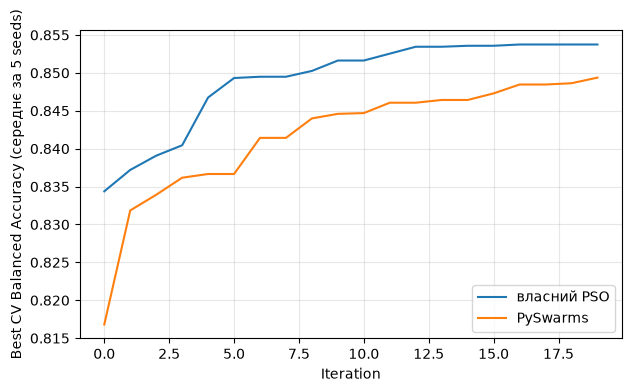

In [ ]:
def own_pso(seed, n_particles=N_PARTICLES, iters=N_ITERATIONS, w=0.7, c1=1.5, c2=1.5):
    rng = np.random.RandomState(seed)
    start = time.time()
    dim = 3
    x = rng.uniform(lower_bounds, upper_bounds, size=(n_particles, dim))
    v = rng.uniform(-(upper_bounds - lower_bounds), upper_bounds - lower_bounds, size=(n_particles, dim)) * 0.1
    cost = objective_function(x)
    pbest, pbest_cost = x.copy(), cost.copy()
    g = np.argmin(pbest_cost)
    gbest, gbest_cost = pbest[g].copy(), pbest_cost[g]
    history = []
    for _ in range(iters):
        r1, r2 = rng.rand(n_particles, dim), rng.rand(n_particles, dim)
        v = w * v + c1 * r1 * (pbest - x) + c2 * r2 * (gbest - x)
        x = np.clip(x + v, lower_bounds, upper_bounds)
        cost = objective_function(x)
        improved = cost < pbest_cost
        pbest[improved], pbest_cost[improved] = x[improved], cost[improved]
        g = np.argmin(pbest_cost)
        if pbest_cost[g] < gbest_cost:
            gbest, gbest_cost = pbest[g].copy(), pbest_cost[g]
        history.append(gbest_cost)
    return {"cost": gbest_cost, "cv": 1.0 - gbest_cost, "position": gbest, "time": time.time() - start,
            "history": history, "seed": seed}

own_runs = [own_pso(s) for s in SEEDS]
print(pd.DataFrame({
    "власний PSO": {"best CV BAcc": f"{np.mean([r['cv'] for r in own_runs]):.4f} ± {np.std([r['cv'] for r in own_runs]):.4f}",
                    "час, с": round(np.mean([r['time'] for r in own_runs]), 1)},
    "PySwarms": {"best CV BAcc": f"{np.mean([r['cv'] for r in base_runs]):.4f} ± {np.std([r['cv'] for r in base_runs]):.4f}",
                 "час, с": round(np.mean([r['time'] for r in base_runs]), 1)}}).T.to_string())

plt.figure(figsize=(7, 4))
plt.plot(np.mean([1.0 - np.array(r["history"]) for r in own_runs], axis=0), label="власний PSO")
plt.plot(mean_curve(base_runs), label="PySwarms")
plt.xlabel("Iteration")
plt.ylabel("Best CV Balanced Accuracy (середнє за 5 seeds)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Власний PSO (формули з теорії для швидкості та позиції, позиції обмежуються межами пошуку, ті самі границі й та сама objective function) дає best CV Balanced Accuracy 0.8537 ± 0.0016 проти 0.8494 ± 0.0042 для PySwarms, час 23.4 і 22.8 с. Різниця (0.0043) порівнянна з розкидом PySwarms, тобто реалізації ведуть себе схоже. Невеликі відмінності очікувані: у власній реалізації початкові швидкості випадкові й малі (10% ширини діапазону), початкова популяція оцінюється окремо, через що робиться на 20 оцінок більше (420 проти 400), і генератори випадкових чисел різні. Графік показує, що обидві траєкторії зростають і виходять на плато.

# Висновки

У цьому практикумі ми навчились формулювати пошук гіперпараметрів SVM як задачу безперервної оптимізації, реалізовувати Particle Swarm Optimization з бібліотекою PySwarms і власним кодом, використовувати 5-кратну крос-валідацію як objective function без використання тестової вибірки та досліджувати вплив параметрів рою на збіжність. Метою роботи було ознайомитися з принципами ройового інтелекту та PSO, реалізувати PSO для автоматичного пошуку гіперпараметрів, дослідити вплив параметрів рою на збіжність та якість розв'язку, а також порівняти PSO з ручною конфігурацією та Random Search за однакового бюджету, і її досягнуто.

**Практичне покращення.** PSO підняв CV Balanced Accuracy з 0.8249 (baseline) до 0.8494 ± 0.0042 у середньому за 5 seeds (близько 2.4 п.п.), найкраща конфігурація має 0.8562. На тесті найкращі варіанти (0.9188 і 0.9340) вищі за baseline (0.9037), проте Local-Best та Random Search з seed 42 нижчі за baseline (0.8734). Оскільки тест має лише 61 об'єкт (одна помилка ≈ 1.5 – 1.8 п.п.), а CV-приріст отримано на тих самих даних, які оптимізувались, практичний приріст є, але невеликий і не гарантований.

**Вплив параметрів.** Менша інерція (w = 0.3) швидше стягує рій (різноманіття 0.12 проти 0.37 при w = 0.7 і 0.45 при w = 1.1) і дала найкращий та найстабільніший результат. Різниця між співвідношеннями c1 і c2 мала (0.8469 – 0.8514) і порівнянна з розкидом між запусками. Більший рій дає кращу та стабільнішу якість (0.8482, 0.8494, 0.8554 для 10, 20, 40 частинок), але час і кількість оцінок зростають пропорційно (11, 23 і 45 с), тому порівняння відбувається не за однакового бюджету. Global-Best і Local-Best практично не відрізнились (0.8494 і 0.8496). PSO перевершив Random Search з тим самим бюджетом (0.8494 проти 0.8454) і виграв у 4 із 5 seeds, але різниця менша за розкид між запусками. Параметри, знайдені в різних запусках, дуже відрізняються, а якість близька, тож пошук відбувається на пласкій ділянці функції. Власна реалізація PSO дала результат, близький до PySwarms (0.8537 ± 0.0016 проти 0.8494 ± 0.0042).

**Обмеження.** Невелика вибірка (303 об'єкти, тест 61), один розподіл на train/test, 5 seeds на кожну серію, а оцінки CV і тесту різняться, тому наведені відмінності між налаштуваннями слід розглядати як тенденції.

# Контрольні питання

**1. У чому полягає основна ідея Particle Swarm Optimization?**

PSO це популяційний стохастичний метод оптимізації, натхненний колективною поведінкою зграї птахів або косяка риб. Кожна частинка є кандидатним розв'язком і рухається у просторі пошуку, а на її рух впливають власний найкращий досвід частинки та найкращий розв'язок, знайдений роєм. Оновлення відбувається за формулами v(t+1) = w · v(t) + c1 · r1 · (pbest − x(t)) + c2 · r2 · (gbest − x(t)) та x(t+1) = x(t) + v(t+1).

**2. Що означають position та velocity частинки?**

Position (позиція) це координати частинки в просторі пошуку, тобто конкретне значення параметрів, що оптимізуються. У цій роботі вона має вигляд [log10(C), log10(gamma), positive_class_weight], який декодується в C, gamma та вагу позитивного класу. Velocity (швидкість) це вектор, що задає зміщення позиції на кожній ітерації: нова позиція дорівнює старій позиції плюс нова швидкість, а швидкість залежить від попередньої швидкості та тяжіння до pbest і gbest.

**3. Чим personal best відрізняється від global best?**

Personal best (pbest) це найкраща позиція, яку знайшла конкретна частинка за весь час пошуку, а global best (gbest) це найкраща позиція, знайдена всім роєм. Перший показує власний досвід частинки, другий колективний досвід рою.

**4. Яку роль відіграє inertia weight w?**

Inertia weight визначає, наскільки частинка зберігає попередню швидкість. Велике w підтримує ширший пошук та інерційний рух (exploration), мале w зменшує інерцію та робить пошук локальнішим (exploitation).

**5. За що відповідають коефіцієнти c1 та c2?**

c1 (cognitive coefficient) підсилює орієнтацію частинки на власний досвід (тяжіння до pbest), c2 (social coefficient) підсилює рух до найкращого глобального рішення (gbest). Надмірне тяжіння до gbest (велике c2) може спричинити передчасну збіжність, а випадкові числа r1 та r2 додають до руху стохастичність.

**6. Що таке exploration–exploitation trade-off?**

Це баланс між дослідженням нових областей простору пошуку (exploration) та поглибленим пошуком навколо вже знайдених добрих рішень (exploitation). У PSO він регулюється параметрами w, c1 та c2: велике w та велике c1 підтримують дослідження, а велике c2 посилює збіжність до найкращого відомого рішення. Надто сильна експлуатація призводить до передчасної збіжності та застрягання в локальному оптимумі, а надто сильне дослідження уповільнює збіжність.

**7. Чим Global-Best PSO концептуально відрізняється від Local-Best PSO?**

У Global-Best PSO кожна частинка використовує інформацію від усього рою (глобальний найкращий розв'язок gbest). У Local-Best PSO вона використовує інформацію лише від локального оточення (k найближчих сусідів, у роботі k = 5). Це може підтримувати різноманіття популяції та знижувати ризик передчасної збіжності, але інколи уповільнює збіжність.

**8. Чому гіперпараметри C і gamma доцільно оптимізувати у логарифмічному просторі?**

Значення цих параметрів можуть відрізнятися на порядки (у роботі C від 0.01 до 1000, gamma від 0.0001 до 10). Пошук у логарифмічному просторі (log10(C), log10(gamma)) дозволяє ефективно досліджувати такі параметри: рівні відстані в логарифмічному просторі відповідають рівним відносним змінам параметра, і весь діапазон покривається рівномірно, а не зосереджується навколо найбільших значень.

**9. Чому test set не можна використовувати в objective function?**

Якщо тестову вибірку використати в objective function, то параметри будуть підібрані під неї, і оцінка на тесті втратить незалежність та стане завищеною. Тому test set відкладається до завершення оптимізації, а оцінювання кожної частинки виконується тільки на training-частині за stratified cross-validation.

**10. Навіщо порівнювати PSO з Random Search при однаковому computational budget?**

Random Search це простий контрольний метод. Якщо PSO при тій самій кількості оцінювань objective function не дає кращого результату, його складність не виправдана. Порівняння при однаковому бюджеті є чесним, бо кількість оцінювань визначає основну обчислювальну вартість, адже кожне оцінювання вимагає навчання моделі за крос-валідацією.